# 23. Kiểm định đồng nhất bắt cặp theo hồ sơ

Các phép kiểm định của tuần 2 và tuần 3 không đồng nhất về tham số. Một số dùng hai nghìn lần lấy mẫu lặp, một số dùng năm nghìn. Khoảng tin cậy sinh ra từ hai tham số khác nhau vẫn đúng về mặt thống kê, nhưng khi đặt cạnh nhau trong cùng một hình hoặc cùng một bảng thì bề rộng của chúng không so sánh được, và người phản biện có quyền hỏi vì sao.

Sổ tay này đọc lại tổng sai số theo từng hồ sơ của mọi lần huấn luyện đã lưu, rồi tính lại tất cả các phép so sánh quan trọng với đúng một bộ tham số: năm nghìn lần lấy mẫu lặp, hạt giống lấy mẫu bằng không, mức tin cậy chín mươi lăm phần trăm, lấy mẫu lặp theo hồ sơ bệnh nhân chứ không theo điểm dữ liệu.

Lấy mẫu theo hồ sơ là lựa chọn bắt buộc chứ không phải tuỳ chọn: các điểm trong cùng một hồ sơ tương quan rất mạnh, nên lấy mẫu theo điểm sẽ cho khoảng tin cậy hẹp giả tạo.

Sổ tay không huấn luyện mô hình nào. Chi phí khoảng bốn phút, phần lớn dành cho việc lấy mẫu lặp.

> **Vị trí trong chuỗi tái lập:** notebook 23 trên tổng số 31. Thứ tự chạy và sơ đồ phụ thuộc nằm trong `README.md`.
>
> **Cần chạy trước:** 03-Tien_xu_ly_va_thuc_nghiem_chinh, 09-Ba_ham_mat_mat_hai_neo, 10-Luoi_nam_hat_giong, 11-Chi_so_theo_nhom_kenh, 12-Phan_tang_theo_do_tre, 13-Moc_trung_binh_dich_chuyen, 14-Doi_chung_moc_manh_nhat, 15-Neo_B_ham_tuyet_doi_nam_hat_giong, 16-Kiem_tra_thang_do_kenh, 17-Neo_theo_nguong_do_phu, 18-Phan_tang_gop_tang_cuoi, 22-Hop_nhat_chi_so.
>
> **Thư mục kết quả:** `Output/processed/w3_artefacts_tong_hop/`.
>
> **Mã định danh nội bộ:** `W3.W4_27`. Mã này còn xuất hiện trong tên khóa JSON, tên hình và nhật ký chạy; nó được giữ nguyên để không phá phép đối chiếu chéo và mã băm của bản khai báo trước.

## 1. Tham số và đường dẫn

In [1]:
#@title Tham số chạy { display-mode: "form" }
PROJECT_DIR = "/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4"  #@param {type:"string"}
READ_TAG = "chot"  #@param {type:"string"}
RUN_TAG = "w3_artefacts_tong_hop"  #@param {type:"string"}
N_BOOT = 5000  #@param {type:"integer"}
HAT_GIONG_LAY_MAU = 0  #@param {type:"integer"}
MUC_ALPHA = 0.05  #@param {type:"number"}
SEQ_LEN = 36     #@param {type:"integer"}
PRED_LEN = 12    #@param {type:"integer"}
N_SEEDS = 3      #@param {type:"integer"}
EPOCHS = 60      #@param {type:"integer"}
PATIENCE = 10    #@param {type:"integer"}
BATCH = 128      #@param {type:"integer"}
LR = 1e-3        #@param {type:"number"}

import os, sys, json, time, random, datetime, platform, importlib, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
else:
    PROJECT_DIR = os.environ.get("P12_PROJECT", "./AIO2026_Conquer_M4_DLinear_NLinear_Slot4")

PROJECT = Path(PROJECT_DIR)
OUT = PROJECT / "Output"
# Đọc dữ liệu đã tiền xử lý của lần chạy chốt, ghi kết quả sang một thư mục con riêng.
PROC = OUT / "processed" / READ_TAG
RUN_DIR = OUT / "processed" / RUN_TAG
RUNS = RUN_DIR / "runs"
FIGS = RUN_DIR / "figures"
LOGS = RUN_DIR / "logs"
for d in (RUN_DIR, RUNS, FIGS, LOGS):
    d.mkdir(parents=True, exist_ok=True)

assert (PROC / "meta.json").exists(), (
    "Không thấy dữ liệu đã tiền xử lý trong " + str(PROC) +
    ". Hãy chạy notebook 03-Tien_xu_ly_va_thuc_nghiem_chinh trước.")
meta = json.loads((PROC / "meta.json").read_text())
channels = meta["channels"]
EPS = 1e-8

print("Thư mục đọc :", PROC)
print("Thư mục ghi :", RUN_DIR)
print("Số kênh     :", len(channels), "| ngưỡng cắt sigma của lần chạy nguồn:", meta["clip_sigma"])


Mounted at /content/drive
Thư mục đọc : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot
Thư mục ghi : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_artefacts_tong_hop
Số kênh     : 37 | ngưỡng cắt sigma của lần chạy nguồn: 0.0


In [2]:
REQUIRED = {"numpy": "1.24.0", "torch": "2.0.0", "matplotlib": "3.7.0", "scipy": "1.10.0"}


def ver_tuple(v):
    out = []
    for part in str(v).split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out + [0] * (3 - len(out)))


missing = []
for name, floor in REQUIRED.items():
    try:
        mod = importlib.import_module(name)
        if ver_tuple(mod.__version__) < ver_tuple(floor):
            missing.append(name + ">=" + floor)
    except ImportError:
        missing.append(name + ">=" + floor)

if missing:
    print("Cài bổ sung:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing, check=True)

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

ENV = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG,
    "read_tag": READ_TAG,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "torch": torch.__version__,
    "matplotlib": matplotlib.__version__,
    "scipy": scipy.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
}
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
(LOGS / ("env_" + stamp + ".json")).write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
for k, v in ENV.items():
    print(k.ljust(12), v)


timestamp    2026-10-14T18:53:29
run_tag      w3_artefacts_tong_hop
read_tag     chot
python       3.13.15
numpy        2.1.3
torch        2.11.0+cu130
matplotlib   3.10.0
scipy        1.16.3
gpu          Tesla T4


In [3]:
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

matplotlib.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "lines.linewidth": 1.4,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "figure.constrained_layout.use": True,
})


def luu_hinh(fig, ten):
    duong = FIGS / ten
    fig.savefig(duong)
    print("Đã lưu", duong)
    return duong


print("Đã đặt quy ước trình bày hình")


Đã đặt quy ước trình bày hình


In [4]:
# Đợt hợp nhất dùng thêm hai thư mục con để tách bảng và gói nộp.
OUT_PROC = OUT / "processed"
BANG = RUN_DIR / "bang"
GOI = RUN_DIR / "goi"
for d in (BANG, GOI):
    d.mkdir(parents=True, exist_ok=True)


def ghi_bang(ten, cot, hang):
    """Ghi một bảng ra tệp CSV, dùng bảng mã có dấu hiệu thứ tự byte cho Excel."""
    import csv
    duong = BANG / ten
    with open(duong, "w", newline="", encoding="utf-8-sig") as f:
        w = csv.writer(f)
        w.writerow(cot)
        for r in hang:
            w.writerow([r.get(k, "") for k in cot])
    print("Đã ghi bảng", ten, "|", len(hang), "dòng |",
          duong.stat().st_size, "byte")
    return duong


def ghi_json(ten, doi_tuong):
    """Ghi một tệp tổng hợp, luôn giữ nguyên dấu tiếng Việt."""
    duong = RUN_DIR / ten
    duong.write_text(json.dumps(doi_tuong, ensure_ascii=False, indent=1),
                     encoding="utf-8")
    print("Đã ghi tệp", ten, "|", duong.stat().st_size, "byte")
    return duong


print("Thư mục bảng:", BANG)
print("Thư mục gói :", GOI)


Thư mục bảng: /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_artefacts_tong_hop/bang
Thư mục gói : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_artefacts_tong_hop/goi


In [5]:
# Danh mục mười lần chạy của tuần 3, khai báo tường minh theo ba thành phần:
# Mã sổ tay, tên thư mục con và tên tệp tổng hợp mà sổ tay đó đã ghi ra.
DANH_MUC_W3 = [
    ("W3_16", "w3_16_ba_ham_mat_mat_hai_neo", "W3_ba_ham_mat_mat_hai_neo.json"),
    ("W3_17", "w3_17_luoi_nam_hat_giong", "W3_luoi_nam_hat_giong.json"),
    ("W3_18", "w3_18_chi_so_theo_nhom_kenh", "W3_chi_so_theo_nhom_kenh.json"),
    ("W3_19", "w3_19_phan_tang_theo_do_tre", "W3_phan_tang_theo_do_tre.json"),
    ("W3_20", "w3_20_moc_trung_binh_dich_chuyen",
     "W3_moc_trung_binh_dich_chuyen.json"),
    ("W3_21", "w3_21_doi_chung_moc_manh_nhat", "W3_doi_chung_moc_manh_nhat.json"),
    ("W3_22", "w3_22_neo_b_ham_tuyet_doi_nam_hat_giong",
     "W3_neo_b_mae_nam_hat_giong.json"),
    ("W3_23", "w3_23_kiem_tra_thang_do_kenh", "W3_kiem_tra_thang_do_kenh.json"),
    ("W3_24", "w3_24_neo_theo_nguong_do_phu", "W3_neo_theo_nguong_do_phu.json"),
    ("W3_25", "w3_25_phan_tang_gop_tang_cuoi",
     "W3_phan_tang_gop_tang_cuoi.json"),
]


def doc_tong_hop(ma):
    """Đọc tệp tổng hợp của một sổ tay tuần 3 theo mã sổ tay."""
    for m, thu_muc, ten_tep in DANH_MUC_W3:
        if m == ma:
            duong = OUT / "processed" / thu_muc / ten_tep
            assert duong.exists(), "Không thấy " + str(duong)
            return json.loads(duong.read_text())
    raise KeyError("Không có mã sổ tay " + str(ma))


CO_MAT, THIEU = [], []
for ma, thu_muc, ten_tep in DANH_MUC_W3:
    duong = OUT / "processed" / thu_muc / ten_tep
    (CO_MAT if duong.exists() else THIEU).append(ma)
print("Lần chạy đã có tệp tổng hợp:", ", ".join(CO_MAT))
print("Lần chạy còn thiếu        :", ", ".join(THIEU) if THIEU else "không có")
assert not THIEU, ("Còn thiếu tệp tổng hợp của " + ", ".join(THIEU) +
                   ". Hãy chạy lại các sổ tay đó trước khi hợp nhất.")


Lần chạy đã có tệp tổng hợp: W3_16, W3_17, W3_18, W3_19, W3_20, W3_21, W3_22, W3_23, W3_24, W3_25
Lần chạy còn thiếu        : không có


## 2. Đọc sổ đăng ký do notebook 22 sinh ra

Sổ tay này không quét lại thư mục. Nó đọc tệp hợp nhất của bước trước, vì nếu mỗi sổ tay tự quét theo cách riêng thì hai sổ tay có thể nhìn thấy hai tập dữ liệu khác nhau, và đó đúng là loại phân mảnh mà đợt này muốn xoá.

In [6]:
TEP_HOP_NHAT = RUN_DIR / "W3_HOP_NHAT_CHI_SO.json"
assert TEP_HOP_NHAT.exists(), (
    "Không thấy " + str(TEP_HOP_NHAT) + ". Hãy chạy notebook 22 trước.")
HOP_NHAT = json.loads(TEP_HOP_NHAT.read_text())
# Chỉ nhận tệp hợp nhất có phạm vi quét khoá ở tuần 3.
assert HOP_NHAT.get("phien_ban_hop_nhat") == "W3.W4_26", (
    "Tệp hợp nhất chưa được sinh từ notebook 22. Hãy chạy notebook 22 trước.")
print("Phạm vi quét của tệp hợp nhất: tới tuần", HOP_NHAT.get("pham_vi_tuan_toi_da"))
assert "nguong_ban_sao" in HOP_NHAT, (
    "Tệp hợp nhất được sinh từ bản W3.W4_26 cũ. Hãy chạy lại notebook 22 bản hiện hành.")
BAN_GHI = HOP_NHAT["tung_lan"]
MSE_MOC = HOP_NHAT["mse_persistence"]
MAE_MOC = HOP_NHAT["mae_persistence"]
print("Số lần huấn luyện trong sổ đăng ký:", len(BAN_GHI))
print("Mốc tham chiếu:", MSE_MOC, "và", MAE_MOC)

THEO_KHOA = {}
for r in BAN_GHI:
    if (r.get("duoc_dung", True) and r["co_tong_theo_ho_so"]
            and Path(r["duong_dan_npz"]).exists()):
        THEO_KHOA.setdefault(r["khoa_cau_hinh"], {})[r["hat_giong"]] = (
            r["duong_dan_npz"])
for khoa in sorted(THEO_KHOA):
    print("   ", khoa.ljust(22), "hạt giống",
          ",".join(str(h) for h in sorted(THEO_KHOA[khoa])))


Phạm vi quét của tệp hợp nhất: tới tuần 3
Số lần huấn luyện trong sổ đăng ký: 101
Mốc tham chiếu: 0.5787542076552471 và 0.4659432814781591
    dlinear|A|huber        hạt giống 0,1,2
    dlinear|A|mae          hạt giống 0,1,2
    dlinear|B|huber        hạt giống 0,1,2,3,4
    dlinear|B|mse          hạt giống 0,1,2,3,4
    nlinear|A|huber        hạt giống 0,1,2,3,4
    nlinear|A|mae          hạt giống 0,1,2,3,4
    nlinear|A|mse          hạt giống 0,1,2,3,4
    nlinear|B|huber        hạt giống 0,1,2,3,4
    nlinear|B|mae          hạt giống 0,1,2,3,4
    nlinear|B|mse          hạt giống 0,1,2,3,4
    nlinear|C|mse          hạt giống 0,1,2,3,4
    nlinear|D|mse          hạt giống 0,1,2,3,4
    nlinear|E|mse          hạt giống 0,1,2
    nlinear|F|mse          hạt giống 0,1,2
    nlinear|O|mse          hạt giống 0,1,2
    nlinear|Z|mse          hạt giống 0,1,2
    nlinear|lai|mse        hạt giống 0,1,2
    nlinear|trung|mse      hạt giống 0,1,2,3,4


## 3. Hàm đọc tổng sai số và hàm lấy mẫu lặp bắt cặp

Trung bình qua các hạt giống được lấy trước khi bắt cặp. Thứ tự này quan trọng: biến thiên do hạt giống không phải đối tượng cần đo trong các phép so sánh neo, nên phải được triệt tiêu trước, nếu không khoảng tin cậy sẽ rộng ra vì một nguồn nhiễu không liên quan tới giả thuyết.

In [7]:
def nap_tong(danh_sach_tep):
    """Đọc nhiều tệp tổng sai số theo hồ sơ rồi lấy trung bình qua hạt giống."""
    ses, aes, dem = [], [], None
    for t in danh_sach_tep:
        t = Path(t)
        assert t.exists(), "Không thấy " + str(t)
        d = np.load(t)
        if dem is None:
            dem = d["n"].astype(np.float64)
        ses.append(d["se"].astype(np.float64))
        aes.append(d["ae"].astype(np.float64))
    return np.mean(ses, axis=0), np.mean(aes, axis=0), dem


def lay_theo_khoa(khoa, so_hat_giong=None):
    """Lấy tổng sai số của một cấu hình, mặc định dùng mọi hạt giống có sẵn."""
    assert khoa in THEO_KHOA, "Không có tổng sai số theo hồ sơ cho " + khoa
    hat = sorted(THEO_KHOA[khoa])
    if so_hat_giong is not None:
        hat = hat[:so_hat_giong]
    return nap_tong([THEO_KHOA[khoa][h] for h in hat]) + (hat,)


print("Đã định nghĩa hàm đọc tổng sai số theo hồ sơ")


Đã định nghĩa hàm đọc tổng sai số theo hồ sơ


In [8]:
def hieu_so_bat_cap(se_a, ae_a, se_b, ae_b, dem, n_boot=2000, seed=0, alpha=0.05):
    """Khoảng tin cậy cho hiệu số hai mô hình, lấy mẫu lại cùng một danh sách bệnh nhân."""
    rng = np.random.default_rng(seed)
    N = len(dem)
    d_mse, d_mae = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        d_mse[b] = (se_a[idx].sum() - se_b[idx].sum()) / mau
        d_mae[b] = (ae_a[idx].sum() - ae_b[idx].sum()) / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    mau_that = dem.sum() + EPS
    return {
        "hieu_mse": float((se_a.sum() - se_b.sum()) / mau_that),
        "hieu_mse_ci": [float(np.percentile(d_mse, lo)), float(np.percentile(d_mse, hi))],
        "hieu_mae": float((ae_a.sum() - ae_b.sum()) / mau_that),
        "hieu_mae_ci": [float(np.percentile(d_mae, lo)), float(np.percentile(d_mae, hi))],
        "p_hai_phia_mse": float(2 * min((d_mse <= 0).mean(), (d_mse >= 0).mean())),
        "p_hai_phia_mae": float(2 * min((d_mae <= 0).mean(), (d_mae >= 0).mean())),
        "mau_bootstrap_mse": d_mse,
        "mau_bootstrap_mae": d_mae,
    }


print("Đã định nghĩa hàm kiểm định bắt cặp")


Đã định nghĩa hàm kiểm định bắt cặp


## 4. Khai báo danh sách phép so sánh

Mỗi phép so sánh được khai báo thành một dòng gồm mã, câu hỏi khoa học, cấu hình bên trái và cấu hình bên phải. Dấu của hiệu số luôn hiểu là bên trái trừ bên phải, nên giá trị âm nghĩa là bên trái tốt hơn. Quy ước dấu được giữ y nguyên từ tuần 2 để không phải diễn giải lại.

Phép nào thiếu dữ liệu sẽ bị bỏ qua kèm lời giải thích, chứ không làm sổ tay dừng, vì mục tiêu ở đây là hợp nhất những gì đã có.

In [9]:
KHAI_BAO = [
    ("S01", "Neo quan sát thật có tốt hơn neo bước cuối khi cùng dùng hàm "
            "bình phương không",
     "nlinear|B|mse", "nlinear|A|mse"),
    ("S02", "Khi cùng dùng hàm Huber, lợi thế của neo quan sát thật còn "
            "giữ không",
     "nlinear|B|huber", "nlinear|A|huber"),
    ("S03", "Khi cùng dùng hàm tuyệt đối, lợi thế của neo quan sát thật "
            "còn giữ không",
     "nlinear|B|mae", "nlinear|A|mae"),
    ("S04", "Trong neo quan sát thật, hàm Huber có hơn hàm bình phương không",
     "nlinear|B|huber", "nlinear|B|mse"),
    ("S05", "Trong neo quan sát thật, hàm tuyệt đối có hơn hàm bình "
            "phương không",
     "nlinear|B|mae", "nlinear|B|mse"),
    ("S06", "Trong neo quan sát thật, hàm tuyệt đối có hơn hàm Huber không",
     "nlinear|B|mae", "nlinear|B|huber"),
    ("S07", "Trong neo bước cuối, hàm Huber có hơn hàm bình phương không",
     "nlinear|A|huber", "nlinear|A|mse"),
    ("S08", "Trong neo bước cuối, hàm tuyệt đối có hơn hàm bình phương không",
     "nlinear|A|mae", "nlinear|A|mse"),
    ("S09", "Luật chọn neo theo độ phủ có hơn neo quan sát thật đồng "
            "nhất không",
     "nlinear|lai|mse", "nlinear|B|mse"),
    ("S10", "Luật chọn neo theo độ phủ có hơn neo bước cuối đồng nhất không",
     "nlinear|lai|mse", "nlinear|A|mse"),
    ("S11", "Nhánh DLinear với neo quan sát thật có khác nhánh NLinear không",
     "dlinear|B|mse", "nlinear|B|mse"),
    ("S12", "Cổng học được dùng chung có hơn neo quan sát thật cố định không",
     "nlinear|C|mse", "nlinear|B|mse"),
    ("S13", "Cổng học được riêng kênh có hơn neo quan sát thật cố định không",
     "nlinear|D|mse", "nlinear|B|mse"),
]

SAN_SANG, BO_QUA = [], []
for ma, cau_hoi, trai, phai in KHAI_BAO:
    thieu = [k for k in (trai, phai) if k not in THEO_KHOA]
    if thieu:
        BO_QUA.append((ma, ", ".join(thieu)))
    else:
        SAN_SANG.append((ma, cau_hoi, trai, phai))
print("Số phép so sánh chạy được:", len(SAN_SANG))
for ma, thieu in BO_QUA:
    print("   bỏ qua", ma, "vì chưa có tổng sai số theo hồ sơ của", thieu)


Số phép so sánh chạy được: 13


## 5. Chạy toàn bộ phép so sánh

Hàm kiểm định trả về cả hai mảng năm nghìn hiệu số bốc lại. Hai mảng này chỉ dùng nội bộ để tính khoảng tin cậy và giá trị p; bản ghi kết quả chỉ giữ số vô hướng và khoảng tin cậy hai đầu, đã chuyển về kiểu Python thuần để ghi được ra JSON và CSV.

Vì mọi phép dùng cùng một hạt giống lấy mẫu, các khoảng tin cậy chia sẻ cùng một bảng chỉ số hồ sơ được bốc. Đây là điều kiện để bề rộng của chúng so sánh được với nhau, và cũng là điều kiện để kết quả tái lập chính xác khi chạy lại.

In [10]:
def ve_python(v):
    """Chuyển số hoặc mảng nhỏ của numpy về kiểu Python thuần để ghi JSON."""
    a = np.asarray(v, dtype=np.float64)
    if a.size == 1:
        return float(a.reshape(-1)[0])
    return [float(x) for x in a.reshape(-1)]


# Ngưỡng phủ tối thiểu: phần điểm nằm trong các hồ sơ khớp số điểm ở cả hai
# phía phải đạt ít nhất mức này thì phép so sánh mới được tính.
NGUONG_PHU = 0.90  #@param {type:"number"}

# Giữ danh sách bỏ qua gốc của ô khai báo để chạy lại ô này không bị nhân đôi.
if "BO_QUA_KHAI_BAO" not in globals():
    BO_QUA_KHAI_BAO = list(BO_QUA)
BO_QUA = list(BO_QUA_KHAI_BAO)

KHOA_BO = ("mau_bootstrap_mse", "mau_bootstrap_mae")
KET_QUA = []
LECH_DIEM = []
for ma, cau_hoi, trai, phai in SAN_SANG:
    se_t, ae_t, dem_t, hat_t = lay_theo_khoa(trai)
    se_p, ae_p, dem_p, hat_p = lay_theo_khoa(phai)

    # Trường hợp 1: khác số hồ sơ thì không có cách bắt cặp hợp lệ, bỏ qua.
    if dem_t.shape != dem_p.shape:
        ly_do = ("khác số hồ sơ: " + str(dem_t.size) + " so với "
                 + str(dem_p.size))
        BO_QUA.append((ma, ly_do))
        print(ma, "| BỎ QUA |", ly_do)
        continue

    # Trường hợp 2: cùng số hồ sơ, kiểm tra số điểm theo từng hồ sơ.
    khop = dem_t == dem_p
    so_lech = int((~khop).sum())
    if so_lech == 0:
        chon = np.ones(dem_t.size, dtype=bool)   # y hệt cách tính cũ
    else:
        chon = khop & (dem_t > 0)
    phu_t = float(dem_t[chon].sum() / (dem_t.sum() + EPS))
    phu_p = float(dem_p[chon].sum() / (dem_p.sum() + EPS))

    if so_lech:
        chenh = dem_t - dem_p
        LECH_DIEM.append({"ma": ma, "ben_trai": trai, "ben_phai": phai,
                          "so_ho_so_lech": so_lech,
                          "tong_diem_trai": int(dem_t.sum()),
                          "tong_diem_phai": int(dem_p.sum()),
                          "chenh_lon_nhat": int(np.abs(chenh).max()),
                          "ho_so_trai_nhieu_hon": int((chenh > 0).sum()),
                          "ho_so_phai_nhieu_hon": int((chenh < 0).sum()),
                          "ty_le_phu_trai": phu_t, "ty_le_phu_phai": phu_p})
        print(ma, "| CẢNH BÁO lệch số điểm ở", so_lech, "trên", dem_t.size,
              "hồ sơ | tổng điểm", int(dem_t.sum()), "so với",
              int(dem_p.sum()), "| chênh lớn nhất", int(np.abs(chenh).max()))
        print("     độ phủ của hồ sơ khớp: trái", round(phu_t, 4),
              "| phải", round(phu_p, 4))

    if min(phu_t, phu_p) < NGUONG_PHU:
        ly_do = ("hồ sơ khớp chỉ phủ " + str(round(min(phu_t, phu_p), 4))
                 + " số điểm, dưới ngưỡng " + str(NGUONG_PHU))
        BO_QUA.append((ma, ly_do))
        print(ma, "| BỎ QUA |", ly_do)
        continue

    kd = hieu_so_bat_cap(se_t[chon], ae_t[chon], se_p[chon], ae_p[chon],
                         dem_t[chon], n_boot=N_BOOT, seed=HAT_GIONG_LAY_MAU,
                         alpha=MUC_ALPHA)
    r = {"ma": ma, "cau_hoi": cau_hoi, "ben_trai": trai, "ben_phai": phai,
         "hat_giong_trai": ",".join(str(h) for h in hat_t),
         "hat_giong_phai": ",".join(str(h) for h in hat_p),
         "so_ho_so": int(chon.sum()),
         "so_diem": int(dem_t[chon].sum()),
         "so_ho_so_goc": int(dem_t.size),
         "so_ho_so_lech_diem": so_lech,
         "ty_le_phu_trai": phu_t,
         "ty_le_phu_phai": phu_p,
         "kieu_bat_cap": "day_du" if so_lech == 0 else "chi_ho_so_khop_diem"}
    for k, v in kd.items():
        if k in KHOA_BO:
            continue
        r[k] = ve_python(v)
    assert len(r["hieu_mse_ci"]) == 2 and len(r["hieu_mae_ci"]) == 2
    KET_QUA.append(r)
    nhan = "" if so_lech == 0 else "  [chỉ hồ sơ khớp điểm]"
    print(ma, "|", trai, "trừ", phai + nhan)
    print("     hiệu bình phương", round(r["hieu_mse"], 6),
          "khoảng", [round(x, 6) for x in r["hieu_mse_ci"]],
          "| giá trị p", r["p_hai_phia_mse"])
    print("     hiệu tuyệt đối", round(r["hieu_mae"], 6),
          "khoảng", [round(x, 6) for x in r["hieu_mae_ci"]],
          "| giá trị p", r["p_hai_phia_mae"])

print("")
print("Số phép đã tính:", len(KET_QUA), "| số phép bỏ qua:", len(BO_QUA))
for ma, ly_do in BO_QUA:
    print("   bỏ qua", ma, "|", ly_do)
if LECH_DIEM:
    print("")
    print("Các phép bị lệch số điểm theo hồ sơ:",
          ", ".join(x["ma"] for x in LECH_DIEM))
    print("Ghi chú: kết quả của các phép này chỉ bắt cặp trên phần hồ sơ khớp")
    print("số điểm, phải báo cáo kèm độ phủ và không gộp chung với các phép")
    print("bắt cặp đầy đủ.")


S01 | nlinear|B|mse trừ nlinear|A|mse
     hiệu bình phương -0.052029 khoảng [-0.059156, -0.044837] | giá trị p 0.0
     hiệu tuyệt đối -0.034097 khoảng [-0.036258, -0.031982] | giá trị p 0.0
S02 | nlinear|B|huber trừ nlinear|A|huber
     hiệu bình phương -0.052853 khoảng [-0.061039, -0.044371] | giá trị p 0.0
     hiệu tuyệt đối -0.035852 khoảng [-0.03831, -0.033473] | giá trị p 0.0
S03 | nlinear|B|mae trừ nlinear|A|mae
     hiệu bình phương -0.050149 khoảng [-0.059907, -0.03967] | giá trị p 0.0
     hiệu tuyệt đối -0.037784 khoảng [-0.04065, -0.034987] | giá trị p 0.0
S04 | nlinear|B|huber trừ nlinear|B|mse
     hiệu bình phương -0.002223 khoảng [-0.003597, -0.000768] | giá trị p 0.004
     hiệu tuyệt đối -0.006362 khoảng [-0.006914, -0.00581] | giá trị p 0.0
S05 | nlinear|B|mae trừ nlinear|B|mse
     hiệu bình phương 0.002864 khoảng [-0.00076, 0.00683] | giá trị p 0.1376
     hiệu tuyệt đối -0.01181 khoảng [-0.013198, -0.010409] | giá trị p 0.0
S06 | nlinear|B|mae trừ nlinear|B|hube

## 6. Phân loại kết luận theo quy tắc cố định

Mỗi phép so sánh được gán một trong ba nhãn, theo đúng một quy tắc áp dụng cho mọi dòng: khoảng tin cậy nằm trọn dưới không thì bên trái thắng; nằm trọn trên không thì bên phải thắng; chứa không thì chưa phân biệt được. Dùng khoảng tin cậy làm căn cứ thay vì chỉ dùng giá trị p giúp giữ được độ lớn của hiệu ứng trong kết luận.

In [11]:
def phan_loai(ci):
    thap, cao = float(ci[0]), float(ci[1])
    if cao < 0.0:
        return "bên trái thắng"
    if thap > 0.0:
        return "bên phải thắng"
    return "chưa phân biệt được"


for r in KET_QUA:
    r["ket_luan_mse"] = phan_loai(r["hieu_mse_ci"])
    r["ket_luan_mae"] = phan_loai(r["hieu_mae_ci"])
    r["cung_ket_luan"] = bool(r["ket_luan_mse"] == r["ket_luan_mae"])

for r in KET_QUA:
    print(r["ma"], "| bình phương:", r["ket_luan_mse"].ljust(22),
          "| tuyệt đối:", r["ket_luan_mae"].ljust(22),
          "| cùng kết luận:", r["cung_ket_luan"])
print("")
nghich = [r["ma"] for r in KET_QUA if not r["cung_ket_luan"]]
print("Số phép cho hai chỉ tiêu cùng kết luận:",
      sum(1 for r in KET_QUA if r["cung_ket_luan"]), "trên", len(KET_QUA))
print("Các phép hai chỉ tiêu không cùng kết luận:",
      ", ".join(nghich) if nghich else "không có")
print("Ghi chú: phép không cùng kết luận cần được báo cáo nguyên dạng, vì đó")
print("là thông tin thật về sự phụ thuộc của kết luận vào chỉ tiêu.")


S01 | bình phương: bên trái thắng         | tuyệt đối: bên trái thắng         | cùng kết luận: True
S02 | bình phương: bên trái thắng         | tuyệt đối: bên trái thắng         | cùng kết luận: True
S03 | bình phương: bên trái thắng         | tuyệt đối: bên trái thắng         | cùng kết luận: True
S04 | bình phương: bên trái thắng         | tuyệt đối: bên trái thắng         | cùng kết luận: True
S05 | bình phương: chưa phân biệt được    | tuyệt đối: bên trái thắng         | cùng kết luận: False
S06 | bình phương: bên phải thắng         | tuyệt đối: bên trái thắng         | cùng kết luận: False
S07 | bình phương: bên trái thắng         | tuyệt đối: bên trái thắng         | cùng kết luận: True
S08 | bình phương: chưa phân biệt được    | tuyệt đối: bên trái thắng         | cùng kết luận: False
S09 | bình phương: bên phải thắng         | tuyệt đối: bên phải thắng         | cùng kết luận: True
S10 | bình phương: bên trái thắng         | tuyệt đối: bên trái thắng         | cùng kết luận: Tr

## 7. Hình hai của báo cáo: biểu đồ khoảng tin cậy

Dạng hình này đặt mọi hiệu số lên cùng một trục cùng một đơn vị, kèm khoảng tin cậy, nên người đọc thấy cùng lúc ba thứ: dấu của hiệu ứng, độ lớn và độ chắc chắn. Nó thay thế được một bảng dài trong bản báo cáo.

Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_artefacts_tong_hop/figures/W3_T02_khoang_tin_cay_hop_nhat.png


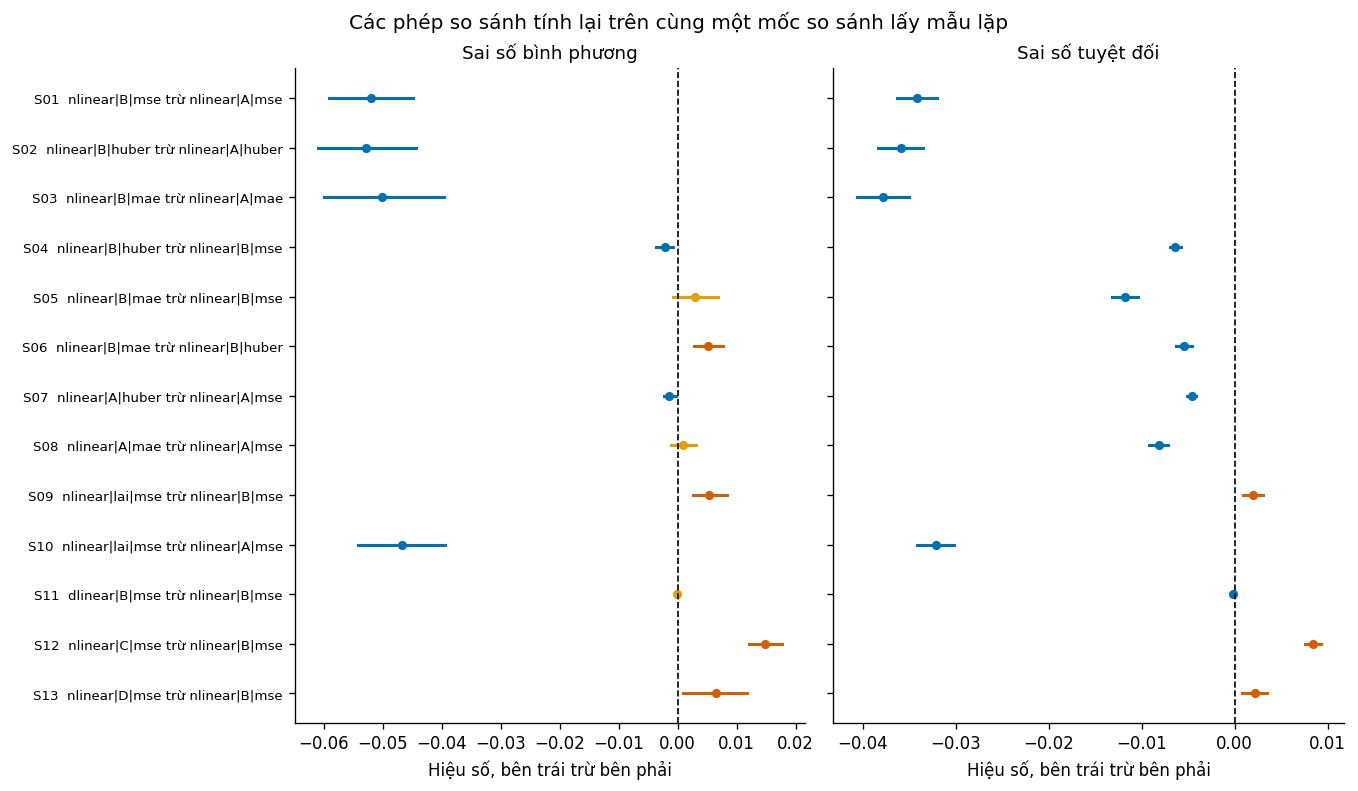

In [12]:
fig, truc = plt.subplots(1, 2, figsize=(11.2, 0.36 * len(KET_QUA) + 1.8),
                         sharey=True)
y = np.arange(len(KET_QUA))
for ax, khoa_hieu, khoa_ci, ten in (
        (truc[0], "hieu_mse", "hieu_mse_ci", "Sai số bình phương"),
        (truc[1], "hieu_mae", "hieu_mae_ci", "Sai số tuyệt đối")):
    tam = np.array([r[khoa_hieu] for r in KET_QUA])
    thap = np.array([r[khoa_ci][0] for r in KET_QUA])
    cao = np.array([r[khoa_ci][1] for r in KET_QUA])
    mau = [PALETTE[0] if c < 0 else (PALETTE[1] if t > 0 else PALETTE[4])
           for t, c in zip(thap, cao)]
    for i in range(len(KET_QUA)):
        ax.plot([thap[i], cao[i]], [y[i], y[i]], color=mau[i], lw=1.8)
        ax.plot([tam[i]], [y[i]], "o", color=mau[i], ms=4.5)
    ax.axvline(0.0, color=PALETTE[6], ls="--", lw=1.0)
    ax.set_xlabel("Hiệu số, bên trái trừ bên phải")
    ax.set_title(ten)
truc[0].set_yticks(y)
truc[0].set_yticklabels([r["ma"] + "  " + r["ben_trai"] + " trừ " +
                         r["ben_phai"] for r in KET_QUA], fontsize=8)
truc[0].invert_yaxis()
fig.suptitle("Các phép so sánh tính lại trên cùng một mốc so sánh lấy mẫu lặp")
luu_hinh(fig, "W3_T02_khoang_tin_cay_hop_nhat.png")
plt.show()


## 8. Ghi bảng kiểm định và cập nhật tệp hợp nhất

Bảng kiểm định được ghi ra riêng, và tệp hợp nhất của bước trước được bổ sung thêm khối kiểm định. Cách làm này giữ nguyên tắc một nguồn sự thật: tệp hợp nhất luôn là bản đầy đủ nhất, các tệp bảng chỉ là hình chiếu của nó cho tiện đọc.

In [13]:
COT_KD = ["ma", "cau_hoi", "ben_trai", "ben_phai", "hat_giong_trai",
          "hat_giong_phai", "so_ho_so", "so_diem", "hieu_mse",
          "hieu_mse_ci", "p_hai_phia_mse", "ket_luan_mse", "hieu_mae",
          "hieu_mae_ci", "p_hai_phia_mae", "ket_luan_mae", "cung_ket_luan"]
ghi_bang("W3_bang_kiem_dinh_hop_nhat.csv", COT_KD, KET_QUA)

HOP_NHAT["kiem_dinh"] = {
    "tinh_lai_luc": datetime.datetime.now().isoformat(timespec="seconds"),
    "n_boot": N_BOOT,
    "hat_giong_lay_mau": HAT_GIONG_LAY_MAU,
    "muc_alpha": MUC_ALPHA,
    "don_vi_lay_mau": "ho_so_benh_nhan",
    "so_phep": len(KET_QUA),
    "bo_qua": [{"ma": m, "thieu": t} for m, t in BO_QUA],
    "ket_qua": KET_QUA,
}
ghi_json("W3_HOP_NHAT_CHI_SO.json", HOP_NHAT)
print("")
print("Bước kế tiếp: chạy notebook 24 để hợp nhất bảng theo kênh và bảng "
      "phân tầng.")


Đã ghi bảng W3_bang_kiem_dinh_hop_nhat.csv | 13 dòng | 4743 byte
Đã ghi tệp W3_HOP_NHAT_CHI_SO.json | 193828 byte

Bước kế tiếp: chạy notebook 24 để hợp nhất bảng theo kênh và bảng phân tầng.
